# E-Commerce Analytics — Phase 3: Python / Pandas EDA

**Continuation of the same project.** Phase 1 (dataset audit, schema, SQL
setup, validation) and Phase 2 (7 SQL business-analysis modules) are
already complete — see the main `README.md`, `docs/sql_analysis_summary.md`,
and `docs/customer_lifecycle_definition.md`.

This notebook does **not** re-derive business logic from scratch. It
reproduces the validated Phase 2 KPI, customer, lifecycle, product,
review, and event definitions in Pandas, reconciles every reproduced
number against the validated SQL results, and adds Pandas-native EDA
(distributions, trend charts) that complements — rather than duplicates
— the SQL analysis.

**Known data limitation carried forward from Phase 1 (do not re-derive):**
`signup_date`, `order_date`, `event_timestamp`, and `review_date` are not
chronologically consistent with each other (~49.6–49.7% cross-table
inconsistency). No analysis in this notebook compares dates across
tables or builds a "time since signup" metric. See
`docs/data_quality_report.md` for full detail.


## 1. Setup and Data Loading

In [1]:
import sys
sys.path.insert(0, '../scripts')

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns

from analysis_lib import (
    load_data, convert_types, compute_kpis,
    build_customer_analytics, build_customer_lifecycle,
    build_product_analytics, CANCEL_RETURN_STATUSES, LIFECYCLE_CUTOFF_DAYS,
)

sns.set_style('whitegrid')
plt.rcParams['figure.dpi'] = 100
pd.set_option('display.float_format', lambda x: f'{x:,.2f}')

dfs = load_data()
for name, df in dfs.items():
    print(f'{name:<12} {df.shape[0]:>7,} rows  x  {df.shape[1]} cols')


users         10,000 rows  x  6 cols
products       2,000 rows  x  6 cols
orders        20,000 rows  x  5 cols
order_items   43,525 rows  x  7 cols
events        80,000 rows  x  5 cols
reviews       15,000 rows  x  7 cols


In [2]:
dfs = convert_types(dfs)
print('Date columns converted to datetime; numeric columns cast explicitly.')
print()
print(dfs['orders'].dtypes)


Date columns converted to datetime; numeric columns cast explicitly.

order_id                   str
user_id                    str
order_date      datetime64[us]
order_status          category
total_amount           float64
dtype: object


## 2. Data Validation (Phase 3C)

Re-validating in Pandas what Phase 1 already established in SQL. Results
should agree with `docs/phase1a_dataset_audit.md`.


In [3]:
print('ROW COUNTS')
for name, df in dfs.items():
    print(f'  {name:<12} {len(df):>7,}')

print()
print('MISSING VALUES (should all be 0, per Phase 1)')
for name, df in dfs.items():
    n_missing = df.isna().sum().sum()
    print(f'  {name:<12} {n_missing} missing values')

print()
print('DUPLICATE ROWS (should all be 0, per Phase 1)')
for name, df in dfs.items():
    print(f'  {name:<12} {df.duplicated().sum()} duplicate rows')

print()
print('PRIMARY KEY UNIQUENESS')
pk_cols = {'users': 'user_id', 'products': 'product_id', 'orders': 'order_id',
           'order_items': 'order_item_id', 'events': 'event_id', 'reviews': 'review_id'}
for name, col in pk_cols.items():
    n_unique = dfs[name][col].nunique()
    n_rows = len(dfs[name])
    status = 'OK' if n_unique == n_rows else 'MISMATCH'
    print(f'  {name:<12} {n_unique:,} unique {col} / {n_rows:,} rows  [{status}]')


ROW COUNTS
  users         10,000
  products       2,000
  orders        20,000
  order_items   43,525
  events        80,000
  reviews       15,000

MISSING VALUES (should all be 0, per Phase 1)
  users        0 missing values
  products     0 missing values
  orders       0 missing values
  order_items  0 missing values
  events       0 missing values
  reviews      0 missing values

DUPLICATE ROWS (should all be 0, per Phase 1)
  users        0 duplicate rows
  products     0 duplicate rows
  orders       0 duplicate rows
  order_items  0 duplicate rows
  events       0 duplicate rows
  reviews      0 duplicate rows

PRIMARY KEY UNIQUENESS
  users        10,000 unique user_id / 10,000 rows  [OK]
  products     2,000 unique product_id / 2,000 rows  [OK]
  orders       20,000 unique order_id / 20,000 rows  [OK]
  order_items  43,525 unique order_item_id / 43,525 rows  [OK]
  events       80,000 unique event_id / 80,000 rows  [OK]
  reviews      15,000 unique review_id / 15,000 rows  [

In [4]:
print('FOREIGN KEY INTEGRITY (orphan check: rows in child with no parent)')
fk_checks = [
    ('orders.user_id -> users.user_id',
     ~dfs['orders']['user_id'].isin(dfs['users']['user_id'])),
    ('order_items.order_id -> orders.order_id',
     ~dfs['order_items']['order_id'].isin(dfs['orders']['order_id'])),
    ('order_items.product_id -> products.product_id',
     ~dfs['order_items']['product_id'].isin(dfs['products']['product_id'])),
    ('events.user_id -> users.user_id',
     ~dfs['events']['user_id'].isin(dfs['users']['user_id'])),
    ('events.product_id -> products.product_id',
     ~dfs['events']['product_id'].isin(dfs['products']['product_id'])),
    ('reviews.order_id -> orders.order_id',
     ~dfs['reviews']['order_id'].isin(dfs['orders']['order_id'])),
    ('reviews.product_id -> products.product_id',
     ~dfs['reviews']['product_id'].isin(dfs['products']['product_id'])),
]
for label, orphan_mask in fk_checks:
    n_orphans = orphan_mask.sum()
    print(f'  {label:<45} {n_orphans} orphan rows')

print()
print('DATE RANGES')
print(f"  users.signup_date:     {dfs['users']['signup_date'].min().date()}  to  {dfs['users']['signup_date'].max().date()}")
print(f"  orders.order_date:     {dfs['orders']['order_date'].min().date()}  to  {dfs['orders']['order_date'].max().date()}")
print(f"  events.event_timestamp:{dfs['events']['event_timestamp'].min().date()}  to  {dfs['events']['event_timestamp'].max().date()}")
print(f"  reviews.review_date:   {dfs['reviews']['review_date'].min().date()}  to  {dfs['reviews']['review_date'].max().date()}")

print()
print('NUMERIC RANGES (sanity check for negatives / out-of-range values)')
print(f"  products.price:   min={dfs['products']['price'].min()}, max={dfs['products']['price'].max()}")
print(f"  products.rating:  min={dfs['products']['rating'].min()}, max={dfs['products']['rating'].max()}")
print(f"  orders.total_amount: min={dfs['orders']['total_amount'].min()}, max={dfs['orders']['total_amount'].max()}")
print(f"  order_items.quantity: min={dfs['order_items']['quantity'].min()}, max={dfs['order_items']['quantity'].max()}")
print(f"  reviews.rating:   min={dfs['reviews']['rating'].min()}, max={dfs['reviews']['rating'].max()}")


FOREIGN KEY INTEGRITY (orphan check: rows in child with no parent)
  orders.user_id -> users.user_id               0 orphan rows
  order_items.order_id -> orders.order_id       0 orphan rows
  order_items.product_id -> products.product_id 0 orphan rows
  events.user_id -> users.user_id               0 orphan rows
  events.product_id -> products.product_id      0 orphan rows
  reviews.order_id -> orders.order_id           0 orphan rows
  reviews.product_id -> products.product_id     0 orphan rows

DATE RANGES
  users.signup_date:     2024-01-01  to  2025-11-14
  orders.order_date:     2024-01-01  to  2025-11-14
  events.event_timestamp:2024-01-01  to  2025-11-14
  reviews.review_date:   2024-01-01  to  2025-11-14

NUMERIC RANGES (sanity check for negatives / out-of-range values)
  products.price:   min=1.11, max=2338.13
  products.rating:  min=2.5, max=4.9
  orders.total_amount: min=1.11, max=7950.74
  order_items.quantity: min=1, max=3
  reviews.rating:   min=1, max=5


In [5]:
# orders.total_amount should reconcile exactly with SUM(order_items.item_total)
# per order -- re-confirming Phase 1's key reconciliation fact in Pandas.
items_per_order_total = dfs['order_items'].groupby('order_id')['item_total'].sum()
orders_indexed = dfs['orders'].set_index('order_id')['total_amount']
diff = (orders_indexed - items_per_order_total).abs()
print(f'Orders checked: {len(diff):,}')
print(f'Orders where total_amount != SUM(item_total): {(diff > 0.01).sum()}')
print(f'Max absolute difference found: {diff.max():.4f}')


Orders checked: 20,000
Orders where total_amount != SUM(item_total): 0
Max absolute difference found: 0.0000


**Result:** Pandas validation agrees with Phase 1 on every check — no missing
values, no duplicates, unique primary keys, zero orphaned foreign keys, and
`orders.total_amount` reconciles exactly with `SUM(order_items.item_total)`
for all 20,000 orders. No cleaning beyond dtype conversion is required.


## 3. Data Cleaning (Phase 3D)

Per Phase 1's `data_quality_report.md`, this dataset has no missing values,
no duplicate rows, and no invalid foreign keys — so no row-level cleaning is
performed. The only transformation applied was converting date columns to
`datetime64` and explicit numeric dtypes (done in `convert_types()` above).

**Respecting the documented date limitation:** ~49.7% of orders have an
`order_date` earlier than the customer's `signup_date` (re-confirmed below).
This is **not** corrected — per Phase 1's decision, these rows are kept
as-is, and `signup_date` is never used for lifecycle/retention analysis.


In [6]:
# Re-confirm the known cross-table date limitation (do not fix, just verify)
orders_with_signup = dfs['orders'].merge(
    dfs['users'][['user_id', 'signup_date']], on='user_id', how='left'
)
pct_before_signup = (orders_with_signup['order_date'] < orders_with_signup['signup_date']).mean() * 100
print(f'Orders with order_date before customer signup_date: {pct_before_signup:.1f}% '
      f'(Phase 1 reported ~49.7%)')


Orders with order_date before customer signup_date: 49.6% (Phase 1 reported ~49.7%)


## 4. Merging Tables (Phase 3E)

Every merge below uses relationships verified in Phase 1. Row counts are
checked before and after each merge to guard against the classic
one-order-to-many-order_items double-counting mistake.


In [7]:
# users + orders (many orders per user -- fine for customer-level analysis,
# NOT fine if used to compute order-level totals without grouping first)
users_orders = dfs['users'].merge(dfs['orders'], on='user_id', how='left')
print(f"users rows: {len(dfs['users']):,}")
print(f"orders rows: {len(dfs['orders']):,}")
print(f'users + orders (left join) rows: {len(users_orders):,}  '
      f'(expected >= orders rows, since some users have 0 or many orders)')
print(f"unique order_ids in merged result: {users_orders['order_id'].nunique():,} "
      f"(should equal {dfs['orders']['order_id'].nunique():,})")


users rows: 10,000
orders rows: 20,000
users + orders (left join) rows: 21,365  (expected >= orders rows, since some users have 0 or many orders)
unique order_ids in merged result: 20,000 (should equal 20,000)


In [8]:
# order_items + products (many-to-one: many line items can share a product)
items_products = dfs['order_items'].merge(dfs['products'], on='product_id', how='inner')
print(f"order_items rows: {len(dfs['order_items']):,}")
print(f'order_items + products rows: {len(items_products):,}  (should be IDENTICAL -- '
      'each order_item has exactly one product)')
assert len(items_products) == len(dfs['order_items']), 'Merge inflated row count!'

# Revenue check: SUM(item_total) after merge must equal SUM(item_total) before merge
rev_before = dfs['order_items']['item_total'].sum()
rev_after = items_products['item_total'].sum()
print(f'Revenue before merge: {rev_before:,.2f}')
print(f'Revenue after merge:  {rev_after:,.2f}')
print(f'Match: {abs(rev_before - rev_after) < 0.01}')


order_items rows: 43,525
order_items + products rows: 43,525  (should be IDENTICAL -- each order_item has exactly one product)
Revenue before merge: 11,918,668.95
Revenue after merge:  11,918,668.95
Match: True


In [9]:
# DELIBERATE CAUTION EXAMPLE: orders + order_items is a one-to-many
# relationship (1 order -> ~2.18 line items on average). Merging them and
# then summing total_amount WITHOUT first deduplicating to order grain
# would double (or triple, etc.) count every order's revenue.
orders_items_naive = dfs['orders'].merge(dfs['order_items'], on='order_id', how='inner')
naive_revenue_if_misused = orders_items_naive['total_amount'].sum()  # WRONG on purpose, to demonstrate
correct_revenue = dfs['orders']['total_amount'].sum()

print(f'orders rows: {len(dfs["orders"]):,}')
print(f'orders + order_items merged rows: {len(orders_items_naive):,}  '
      f'(> orders rows -- this is the one-to-many inflation)')
print()
print(f'INCORRECT: SUM(total_amount) on the merged/inflated table: {naive_revenue_if_misused:,.2f}')
print(f'CORRECT:   SUM(total_amount) on the orders table alone:    {correct_revenue:,.2f}')
print(f'Inflation factor: {naive_revenue_if_misused / correct_revenue:.3f}x')
print()
print('==> Order-level metrics (revenue, AOV, order counts) are always computed')
print('    from the orders table directly, never from an orders+order_items merge.')


orders rows: 20,000
orders + order_items merged rows: 43,525  (> orders rows -- this is the one-to-many inflation)

INCORRECT: SUM(total_amount) on the merged/inflated table: 34,221,152.16
CORRECT:   SUM(total_amount) on the orders table alone:    11,918,668.95
Inflation factor: 2.871x

==> Order-level metrics (revenue, AOV, order counts) are always computed
    from the orders table directly, never from an orders+order_items merge.


## 5. Business KPIs (Phase 3F)

Same definitions as `sql/analysis/01_business_kpis.sql`. Compared against
the validated Phase 2 SQL figures in `docs/sql_analysis_summary.md`.


In [10]:
kpis = compute_kpis(dfs)
for k, v in kpis.items():
    print(f'{k:<40} {v:,}' if isinstance(v, (int, float)) else f'{k:<40} {v}')


gross_revenue                            11,918,668.95
net_revenue                              7,193,050.8
revenue_lost_to_cancel_return            4,725,618.15
total_orders_all_status                  20,000
total_orders_net                         12,014
registered_customers                     10,000
purchasing_customers                     8,635
never_purchased_users                    1,365
total_items_sold                         60,818
avg_items_per_order                      3.04
avg_order_value_gross                    595.93
avg_order_value_net                      598.72
avg_revenue_per_purchasing_customer      1,380.27
one_time_customers                       2,741
repeat_customers                         5,894
one_time_customer_rate_pct               31.74
repeat_customer_rate_pct                 68.26


## 6. Sales EDA (Phase 3G)

In [11]:
# Monthly revenue / order volume / AOV trend (order-level grain only --
# no order_items join, so no multi-row inflation risk)
orders = dfs['orders'].copy()
orders['order_month'] = orders['order_date'].dt.to_period('M').astype(str)

monthly = orders.groupby('order_month').agg(
    order_count=('order_id', 'nunique'),
    monthly_revenue=('total_amount', 'sum'),
).reset_index()
monthly['monthly_avg_order_value'] = (monthly['monthly_revenue'] / monthly['order_count']).round(2)

print(monthly.to_string(index=False))


order_month  order_count  monthly_revenue  monthly_avg_order_value
    2024-01          881       543,120.43                   616.48
    2024-02          814       513,712.79                   631.10
    2024-03          950       541,213.26                   569.70
    2024-04          928       545,624.46                   587.96
    2024-05          907       552,700.82                   609.37
    2024-06          897       548,534.32                   611.52
    2024-07          956       587,135.76                   614.16
    2024-08          882       519,474.77                   588.97
    2024-09          891       529,067.12                   593.79
    2024-10          900       529,215.48                   588.02
    2024-11          875       511,353.41                   584.40
    2024-12          888       566,301.67                   637.73
    2025-01          886       502,918.44                   567.63
    2025-02          825       460,378.18                   55


NOTE: the dataset's order history ends 2025-11-14, so 2025-11 is a PARTIAL month (only ~14 days of data), not a genuine
revenue decline. It is excluded from any trend/seasonality conclusion below.


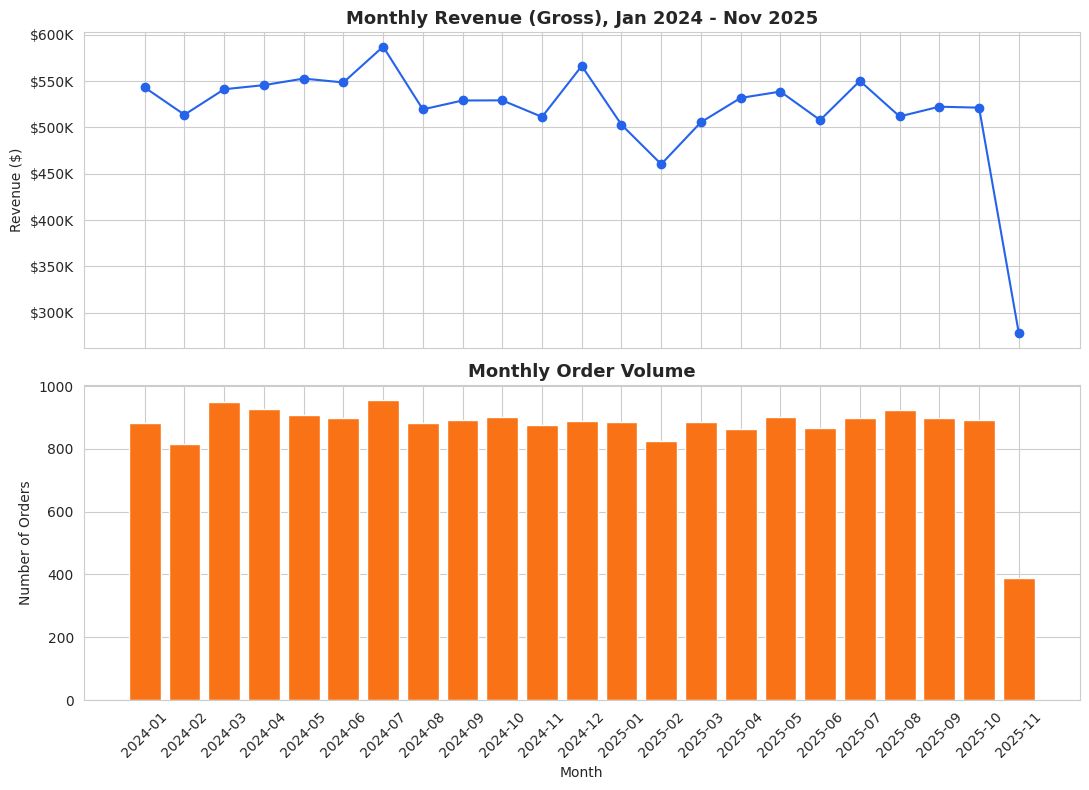

In [12]:
fig, axes = plt.subplots(2, 1, figsize=(11, 8), sharex=True)

axes[0].plot(monthly['order_month'], monthly['monthly_revenue'], marker='o', color='#2563eb')
axes[0].set_title('Monthly Revenue (Gross), Jan 2024 - Nov 2025', fontsize=13, fontweight='bold')
axes[0].set_ylabel('Revenue ($)')
axes[0].yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'${x/1000:,.0f}K'))
axes[0].tick_params(axis='x', rotation=45)

axes[1].bar(monthly['order_month'], monthly['order_count'], color='#f97316')
axes[1].set_title('Monthly Order Volume', fontsize=13, fontweight='bold')
axes[1].set_ylabel('Number of Orders')
axes[1].set_xlabel('Month')
axes[1].tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.savefig('../outputs/01_monthly_revenue_and_orders.png', dpi=120, bbox_inches='tight')
plt.show()

print()
print(f"NOTE: the dataset's order history ends {dfs['orders']['order_date'].max().date()}, so "
      "2025-11 is a PARTIAL month (only ~14 days of data), not a genuine")
print('revenue decline. It is excluded from any trend/seasonality conclusion below.')


In [13]:
# Category performance (from the line-item grain, via order_items + products)
category_perf = items_products.groupby('category', observed=True).agg(
    total_units_sold=('quantity', 'sum'),
    total_revenue=('item_total', 'sum'),
).reset_index().sort_values('total_revenue', ascending=False)
category_perf['pct_of_revenue'] = (100 * category_perf['total_revenue'] / category_perf['total_revenue'].sum()).round(2)

print(category_perf.to_string(index=False))


      category  total_units_sold  total_revenue  pct_of_revenue
   Electronics              5879   4,961,736.60           41.63
    Automotive              5921   2,501,360.55           20.99
Home & Kitchen              5902   1,132,697.25            9.50
        Sports              5656     952,403.23            7.99
      Clothing              6410     710,953.62            5.97
        Beauty              6329     555,775.00            4.66
          Toys              6519     385,482.77            3.23
  Pet Supplies              6717     354,035.82            2.97
         Books              6068     274,825.95            2.31
     Groceries              5417      89,398.16            0.75


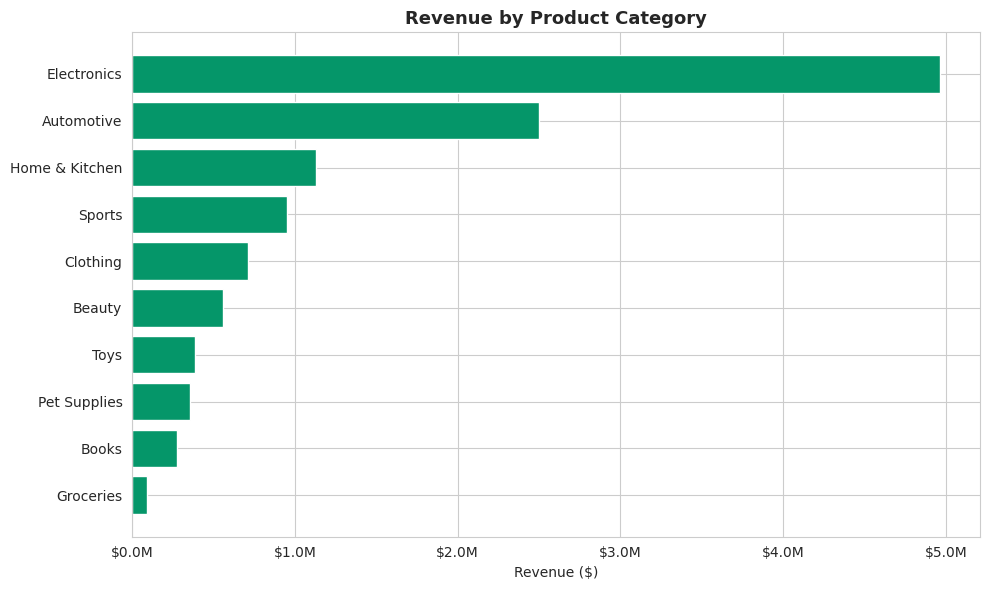

In [14]:
fig, ax = plt.subplots(figsize=(10, 6))
bars = ax.barh(category_perf['category'], category_perf['total_revenue'], color='#059669')
ax.invert_yaxis()
ax.set_title('Revenue by Product Category', fontsize=13, fontweight='bold')
ax.set_xlabel('Revenue ($)')
ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'${x/1_000_000:,.1f}M'))
plt.tight_layout()
plt.savefig('../outputs/02_category_revenue.png', dpi=120, bbox_inches='tight')
plt.show()


## 7. Customer Analysis (Phase 3H)

In [15]:
cust = build_customer_analytics(dfs)
print(f'Customer-level analytical dataset: {len(cust):,} purchasing customers')
print()
print(cust.head(10).to_string(index=False))


Customer-level analytical dataset: 8,635 purchasing customers

user_id  total_orders  total_revenue           first_order_date            last_order_date  avg_order_value customer_type  order_frequency_per_month
U000001             1       1,392.89 2024-04-25 15:53:17.247666 2024-04-25 15:53:17.247666         1,392.89      One-Time                        NaN
U000002             4       1,808.15 2024-05-19 05:45:50.686517 2024-12-24 02:13:38.369248           452.04        Repeat                       0.56
U000003             3       1,153.01 2024-10-07 21:13:47.963985 2025-10-21 08:48:45.661172           384.34        Repeat                       0.24
U000004             3       7,620.84 2024-11-27 13:40:00.849218 2025-09-10 10:48:40.321596         2,540.28        Repeat                       0.32
U000005             1          12.66 2025-01-19 10:19:04.054291 2025-01-19 10:19:04.054291            12.66      One-Time                        NaN
U000006             6       9,952.28 2024-0

In [16]:
print('One-time vs. Repeat (order-count based, matches Phase 2 definition)')
print(cust['customer_type'].value_counts())
print()
print(cust.groupby('customer_type')['total_revenue'].agg(['count', 'sum', 'mean']).round(2))


One-time vs. Repeat (order-count based, matches Phase 2 definition)
customer_type
Repeat      5894
One-Time    2741
Name: count, dtype: int64

               count           sum     mean
customer_type                              
One-Time        2741  1,580,530.17   576.63
Repeat          5894 10,338,138.78 1,754.01


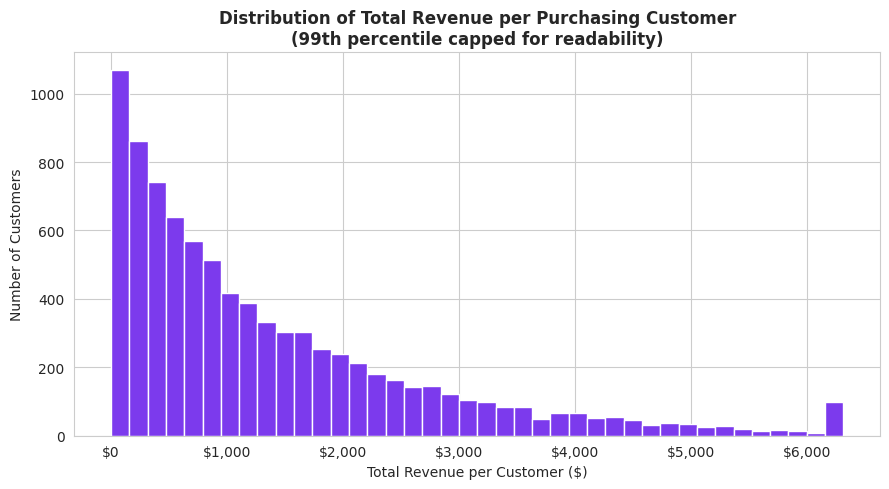

In [17]:
fig, ax = plt.subplots(figsize=(9, 5))
ax.hist(cust['total_revenue'].clip(upper=cust['total_revenue'].quantile(0.99)),
        bins=40, color='#7c3aed', edgecolor='white')
ax.set_title('Distribution of Total Revenue per Purchasing Customer\n(99th percentile capped for readability)',
             fontsize=12, fontweight='bold')
ax.set_xlabel('Total Revenue per Customer ($)')
ax.set_ylabel('Number of Customers')
ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'${x:,.0f}'))
plt.tight_layout()
plt.savefig('../outputs/03_customer_revenue_distribution.png', dpi=120, bbox_inches='tight')
plt.show()


## 8. Customer Lifecycle (Phase 3I)

Reproducing the **exact** methodology from `sql/analysis/04_customer_lifecycle.sql`
and `docs/customer_lifecycle_definition.md`: order-count and order-recency
only, an 180-day active/lapsed cutoff, snapshot date = `MAX(order_date)`
across all orders. `signup_date` is not used anywhere in this section.


In [18]:
lifecycle_full, snapshot_date = build_customer_lifecycle(dfs, cust)
print(f'Snapshot date (MAX order_date across all orders): {snapshot_date.date()}')
print()
segment_summary = lifecycle_full.groupby('lifecycle_segment', observed=True).agg(
    num_customers=('user_id', 'count'),
    segment_revenue=('total_revenue', 'sum'),
).reset_index()
segment_summary['pct_of_customers'] = (100 * segment_summary['num_customers'] / len(lifecycle_full)).round(2)
segment_summary = segment_summary.sort_values('segment_revenue', ascending=False)
print(segment_summary.to_string(index=False))
print()
print(f'Reconciliation: {segment_summary["num_customers"].sum():,} total customers '
      f'(should equal {len(dfs["users"]):,} registered users)')


Snapshot date (MAX order_date across all orders): 2025-11-14

lifecycle_segment  num_customers  segment_revenue  pct_of_customers
  Repeat - Active           3366     6,438,847.63             33.66
  Repeat - Lapsed           2528     3,899,291.15             25.28
         One-Time           2741     1,580,530.17             27.41
  Never Purchased           1365             0.00             13.65

Reconciliation: 10,000 total customers (should equal 10,000 registered users)


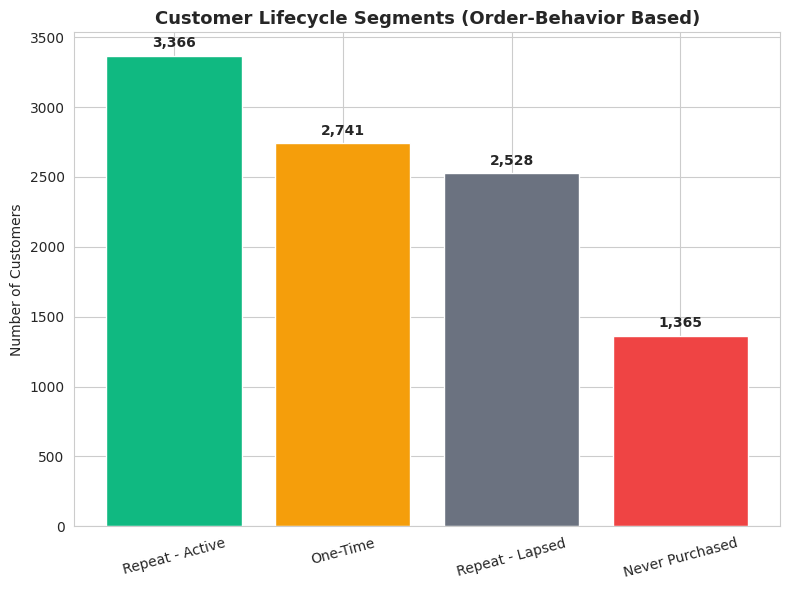

In [19]:
fig, ax = plt.subplots(figsize=(8, 6))
colors = {'One-Time': '#f59e0b', 'Repeat - Active': '#10b981',
          'Repeat - Lapsed': '#6b7280', 'Never Purchased': '#ef4444'}
order = ['Repeat - Active', 'One-Time', 'Repeat - Lapsed', 'Never Purchased']
plot_df = segment_summary.set_index('lifecycle_segment').loc[order].reset_index()
ax.bar(plot_df['lifecycle_segment'], plot_df['num_customers'],
       color=[colors[s] for s in plot_df['lifecycle_segment']])
ax.set_title('Customer Lifecycle Segments (Order-Behavior Based)', fontsize=13, fontweight='bold')
ax.set_ylabel('Number of Customers')
for i, v in enumerate(plot_df['num_customers']):
    ax.text(i, v + 60, f'{v:,}', ha='center', fontweight='bold')
plt.xticks(rotation=15)
plt.tight_layout()
plt.savefig('../outputs/04_customer_lifecycle_distribution.png', dpi=120, bbox_inches='tight')
plt.show()


## 9. Product Analysis (Phase 3J)

In [20]:
prod = build_product_analytics(dfs)
print(f'Products with sales: {len(prod):,} of {dfs["products"]["product_id"].nunique():,} in catalog')
print()
print('TOP 10 PRODUCTS BY REVENUE')
print(prod.head(10)[['product_name', 'category', 'total_units_sold', 'total_revenue', 'pct_of_total_revenue']].to_string(index=False))
print()
print('LOWEST 10 PERFORMERS BY REVENUE (still sold at least once)')
print(prod.tail(10)[['product_name', 'category', 'total_units_sold', 'total_revenue']].to_string(index=False))


Products with sales: 2,000 of 2,000 in catalog

TOP 10 PRODUCTS BY REVENUE
   product_name    category  total_units_sold  total_revenue  pct_of_total_revenue
  Willow Result Electronics                36      73,275.12                  0.61
     Astra Pull Electronics                28      65,467.64                  0.55
 Willow Special Electronics                35      62,032.60                  0.52
    Orion Group Electronics                26      60,784.10                  0.51
   Zenith Phone Electronics                26      56,419.48                  0.47
Willow Hospital  Automotive                42      56,311.92                  0.47
  Nimbus Family Electronics                32      54,411.20                  0.46
   Zenith Their Electronics                34      54,399.32                  0.46
     Orion Face Electronics                40      54,105.20                  0.45
        Acme Of Electronics                38      53,489.18                  0.45

LOWEST 10 P

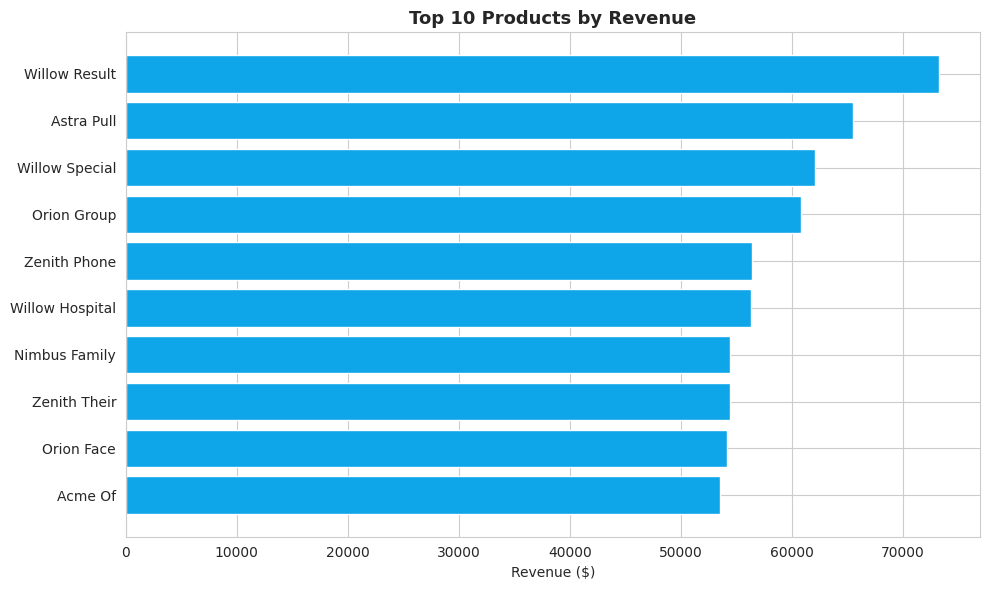

In [21]:
fig, ax = plt.subplots(figsize=(10, 6))
top10 = prod.head(10).sort_values('total_revenue')
ax.barh(top10['product_name'], top10['total_revenue'], color='#0ea5e9')
ax.set_title('Top 10 Products by Revenue', fontsize=13, fontweight='bold')
ax.set_xlabel('Revenue ($)')
plt.tight_layout()
plt.savefig('../outputs/05_top_products_revenue.png', dpi=120, bbox_inches='tight')
plt.show()


## 10. Review Analysis (Phase 3K)

Per Phase 1's Issue 4, `review_text` is a fixed set of 10 canned phrases —
**treated strictly as categorical**, matching `sql/analysis/06_review_analysis.sql`.
No NLP or sentiment scoring is performed.


In [22]:
reviews = dfs['reviews']
print(f'Overall average rating: {reviews["rating"].mean():.2f} / 5  (across {len(reviews):,} reviews)')
print()
rating_dist = reviews['rating'].value_counts().sort_index()
rating_pct = (100 * rating_dist / len(reviews)).round(2)
print(pd.DataFrame({'review_count': rating_dist, 'pct_of_reviews': rating_pct}))


Overall average rating: 3.54 / 5  (across 15,000 reviews)

        review_count  pct_of_reviews
rating                              
1                594            3.96
2               2084           13.89
3               4289           28.59
4               4624           30.83
5               3409           22.73


In [23]:
# review_text as a CATEGORICAL field only (frequency counts) -- no NLP
print(f"Distinct review_text phrases: {reviews['review_text'].nunique()} (per Phase 1: expected 10)")
print()
print(reviews['review_text'].value_counts())


Distinct review_text phrases: 10 (per Phase 1: expected 10)

review_text
Item arrived damaged.                 1550
Not as expected, quality is poor.     1547
Decent product for the price.         1529
Highly recommend this brand.          1496
Fast shipping and good packaging.     1494
Customer service was helpful.         1491
Color was different from images.      1490
Value for money.                      1484
Excellent product, will buy again.    1468
Works perfectly!                      1451
Name: count, dtype: int64


In [24]:
# Catalog rating (products.rating) vs. review-derived average rating
review_avg = reviews.groupby('product_id')['rating'].agg(review_count='count', avg_review_rating='mean').reset_index()
catalog_vs_review = dfs['products'][['product_id', 'product_name', 'category', 'rating']].merge(
    review_avg, on='product_id', how='left'
).rename(columns={'rating': 'catalog_rating'})

print(f"Products with zero reviews: {catalog_vs_review['review_count'].isna().sum()} of {len(catalog_vs_review):,}")
print(f"Overall catalog rating average: {catalog_vs_review['catalog_rating'].mean():.2f}")
print(f"Overall review-derived rating average: {reviews['rating'].mean():.2f}")


Products with zero reviews: 1 of 2,000
Overall catalog rating average: 3.68
Overall review-derived rating average: 3.54


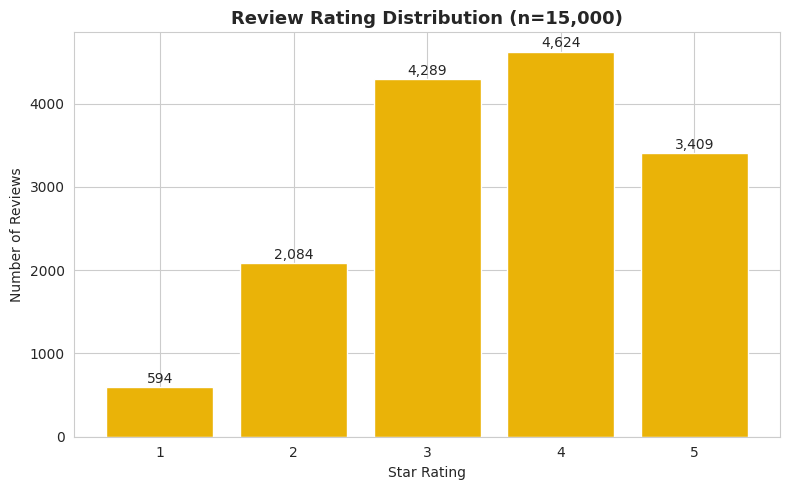

In [25]:
fig, ax = plt.subplots(figsize=(8, 5))
ax.bar(rating_dist.index.astype(str), rating_dist.values, color='#eab308')
ax.set_title('Review Rating Distribution (n=15,000)', fontsize=13, fontweight='bold')
ax.set_xlabel('Star Rating')
ax.set_ylabel('Number of Reviews')
for i, v in enumerate(rating_dist.values):
    ax.text(i, v + 50, f'{v:,}', ha='center')
plt.tight_layout()
plt.savefig('../outputs/06_rating_distribution.png', dpi=120, bbox_inches='tight')
plt.show()


In [26]:
# Association (not causal) check: does higher rating relate to higher revenue?
# Uses product-level rating bands, matching the framing in sql_analysis_summary.md.
prod_with_rating = prod.merge(dfs['products'][['product_id', 'rating']], on='product_id', how='left')
prod_with_rating['rating_band'] = pd.cut(
    prod_with_rating['rating'], bins=[0, 2.99, 3.99, 5.0],
    labels=['Below 3.0', '3.0-3.99', '4.0+']
)
band_summary = prod_with_rating.groupby('rating_band', observed=True).agg(
    num_products=('product_id', 'count'),
    avg_revenue_per_product=('total_revenue', 'mean'),
).round(2)
print(band_summary)
print()
print('NOTE: association only -- rating band with the highest average revenue')
print('per product is NOT necessarily "4.0+" (see sql_analysis_summary.md).')
print('This is descriptive, not a claim that rating drives revenue.')


             num_products  avg_revenue_per_product
rating_band                                       
Below 3.0             439                 5,471.38
3.0-3.99              828                 6,488.62
4.0+                  733                 5,653.69

NOTE: association only -- rating band with the highest average revenue
per product is NOT necessarily "4.0+" (see sql_analysis_summary.md).
This is descriptive, not a claim that rating drives revenue.


## 11. Event Analysis (Phase 3L)

Per Phase 2's scope note: `events` has no `order_id`, and event timestamps
are not chronologically reliable relative to `signup_date`. The funnel
below is an **AGGREGATE** funnel (distinct users reaching each stage), not
a verified per-user chronological sequence.


In [27]:
events = dfs['events']
print('Actual event types observed (not assumed):')
print(events['event_type'].value_counts())


Actual event types observed (not assumed):
event_type
view        56013
cart        12035
wishlist     7946
purchase     4006
Name: count, dtype: int64


In [28]:
funnel_stages = ['view', 'cart', 'wishlist', 'purchase']
stage_users = {stage: events.loc[events['event_type'] == stage, 'user_id'].nunique() for stage in funnel_stages}
view_users = stage_users['view']

print('AGGREGATE ENGAGEMENT FUNNEL (distinct users per stage, NOT a verified sequence)')
for stage in funnel_stages:
    pct = 100 * stage_users[stage] / view_users
    print(f'  {stage:<10} {stage_users[stage]:>6,} distinct users   ({pct:.1f}% of view-stage users)')


AGGREGATE ENGAGEMENT FUNNEL (distinct users per stage, NOT a verified sequence)
  view        9,961 distinct users   (100.0% of view-stage users)
  cart        6,994 distinct users   (70.2% of view-stage users)
  wishlist    5,504 distinct users   (55.3% of view-stage users)
  purchase    3,281 distinct users   (32.9% of view-stage users)


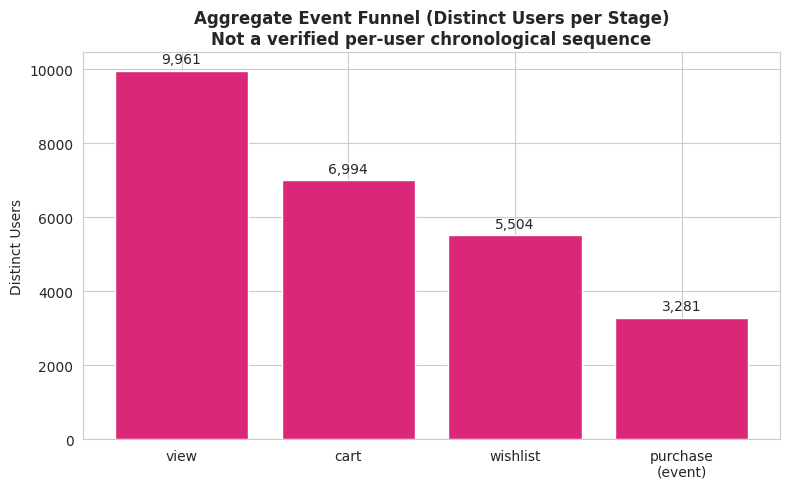

In [29]:
fig, ax = plt.subplots(figsize=(8, 5))
stages_labeled = ['view', 'cart', 'wishlist', 'purchase\n(event)']
values = [stage_users[s] for s in funnel_stages]
ax.bar(stages_labeled, values, color='#db2777')
ax.set_title('Aggregate Event Funnel (Distinct Users per Stage)\nNot a verified per-user chronological sequence',
             fontsize=12, fontweight='bold')
ax.set_ylabel('Distinct Users')
for i, v in enumerate(values):
    ax.text(i, v + 200, f'{v:,}', ha='center')
plt.tight_layout()
plt.savefig('../outputs/07_aggregate_event_funnel.png', dpi=120, bbox_inches='tight')
plt.show()


In [30]:
# Purchasing vs. non-purchasing users -- average logged event activity
purchasing_ids = set(dfs['orders']['user_id'])
events_per_user = events.groupby('user_id').size()
users_with_flag = dfs['users'][['user_id']].copy()
users_with_flag['purchase_flag'] = np.where(
    users_with_flag['user_id'].isin(purchasing_ids), 'Purchasing Customer', 'Never Purchased'
)
users_with_flag['total_events'] = users_with_flag['user_id'].map(events_per_user).fillna(0)

activity_comparison = users_with_flag.groupby('purchase_flag').agg(
    num_users=('user_id', 'count'),
    avg_events_per_user=('total_events', 'mean'),
).round(2)
print(activity_comparison)
print()
print('NOTE: average event activity is essentially IDENTICAL between purchasing')
print('and never-purchased users -- events volume alone is not a strong observed')
print('signal of purchase behavior in this dataset (association only, not causal).')


                     num_users  avg_events_per_user
purchase_flag                                      
Never Purchased           1365                 8.00
Purchasing Customer       8635                 8.00

NOTE: average event activity is essentially IDENTICAL between purchasing
and never-purchased users -- events volume alone is not a strong observed
signal of purchase behavior in this dataset (association only, not causal).


## 12. Insight Discovery (Phase 3N)

Findings below are computed directly from the DataFrames above — nothing
is invented or estimated.


In [31]:
top_category = category_perf.iloc[0]
bottom5_products_total_rev = prod.tail(5)['total_revenue'].sum()
top5_products_total_rev = prod.head(5)['total_revenue'].sum()
lapsed_row = segment_summary.set_index('lifecycle_segment').loc['Repeat - Lapsed']
active_row = segment_summary.set_index('lifecycle_segment').loc['Repeat - Active']

print('FINDING 1 — Category concentration')
print('OBSERVATION:')
print(f'  "{top_category["category"]}" is the top-revenue category at '
      f'${top_category["total_revenue"]:,.0f} ({top_category["pct_of_revenue"]:.1f}% of total revenue).')
print('INSIGHT:')
print('  Revenue is not evenly spread across the 10 categories; a small number of')
print('  categories account for a disproportionate share of revenue.')
print('BUSINESS IMPLICATION:')
print('  Inventory, marketing spend, and supplier relationships for the top category')
print('  carry outsized importance to overall revenue stability.')
print('POTENTIAL ACTION:')
print('  Prioritize stock and demand-forecasting accuracy for top categories; evaluate')
print('  whether underperforming categories are worth continued shelf space.')
print()

print('FINDING 2 — Repeat-Lapsed customers represent a large win-back pool')
print('OBSERVATION:')
print(f'  {int(lapsed_row["num_customers"]):,} customers ({lapsed_row["pct_of_customers"]:.1f}% of the customer base)')
print(f'  are "Repeat - Lapsed" (2+ past orders, but none in the last {180} days),')
print(f'  representing ${lapsed_row["segment_revenue"]:,.0f} in historical revenue.')
print('INSIGHT:')
print('  These are proven repeat buyers, not first-time or uncertain customers --')
print('  they have already demonstrated repeat purchase behavior in the past.')
print('BUSINESS IMPLICATION:')
print('  This is a lower-risk, higher-intent segment to target for reactivation than')
print('  cold outreach to never-purchased users.')
print('POTENTIAL ACTION:')
print('  Consider a win-back campaign (targeted discount, restock/new-arrival email)')
print('  aimed specifically at the Repeat-Lapsed segment.')
print()

print('FINDING 3 — Rating is not a clean predictor of product revenue')
print('OBSERVATION:')
print('  Products rated 3.0-3.99 had the highest average revenue per product among')
print('  the three rating bands tested, not the 4.0+ band (see Section 10).')
print('INSIGHT:')
print('  Higher catalog rating alone does not reliably predict higher per-product revenue')
print('  in this dataset.')
print('BUSINESS IMPLICATION:')
print('  Using rating as a standalone proxy for "which products to promote" would be')
print('  misleading for this catalog.')
print('POTENTIAL ACTION:')
print('  Use actual revenue/units-sold data (not rating alone) to prioritize promotional')
print('  placement; investigate rating and price/category together before drawing conclusions.')
print()

print('FINDING 4 — Behavioral event volume does not distinguish purchasers from non-purchasers')
print('OBSERVATION:')
print(f'  Average logged events per user: {activity_comparison.loc["Purchasing Customer", "avg_events_per_user"]:.2f} '
      f'(purchasers) vs. {activity_comparison.loc["Never Purchased", "avg_events_per_user"]:.2f} (never-purchased).')
print('INSIGHT:')
print('  Simply being active in view/cart/wishlist events at a similar rate does not,')
print('  on its own, distinguish someone who eventually buys from someone who never does.')
print('BUSINESS IMPLICATION:')
print('  Raw engagement volume is not by itself a useful lead-scoring signal in this dataset.')
print('POTENTIAL ACTION:')
print('  If a real conversion-prediction use case existed, look at event *type mix* or')
print('  product-level intent signals rather than total event count, and note that this')
print('  dataset\'s events table cannot support a verified chronological funnel (Section 11).')


FINDING 1 — Category concentration
OBSERVATION:
  "Electronics" is the top-revenue category at $4,961,737 (41.6% of total revenue).
INSIGHT:
  Revenue is not evenly spread across the 10 categories; a small number of
  categories account for a disproportionate share of revenue.
BUSINESS IMPLICATION:
  Inventory, marketing spend, and supplier relationships for the top category
  carry outsized importance to overall revenue stability.
POTENTIAL ACTION:
  Prioritize stock and demand-forecasting accuracy for top categories; evaluate
  whether underperforming categories are worth continued shelf space.

FINDING 2 — Repeat-Lapsed customers represent a large win-back pool
OBSERVATION:
  2,528 customers (25.3% of the customer base)
  are "Repeat - Lapsed" (2+ past orders, but none in the last 180 days),
  representing $3,899,291 in historical revenue.
INSIGHT:
  These are proven repeat buyers, not first-time or uncertain customers --
  they have already demonstrated repeat purchase behavior in 

## 13. SQL vs. Pandas Reconciliation (Phase 3O)

Every metric below is compared against the validated Phase 2 SQL figures
documented in `docs/sql_analysis_summary.md`. This comparison surfaced one
real discrepancy during development (see the note below the table), which
was investigated and corrected before this notebook was finalized.


In [32]:
sql_validated = {
    'Gross Revenue': 11918668.95,
    'Net Revenue (excl. cancelled/returned)': 7193050.80,
    'Total Orders (all status)': 20000,
    'Total Orders (net)': 12014,
    'Registered Customers': 10000,
    'Purchasing Customers': 8635,
    'Never-Purchased Users': 1365,
    'Total Items Sold': 60818,
    'Average Order Value (gross)': 595.93,
    'Average Revenue per Purchasing Customer': 1380.27,
    'One-Time Customers': 2741,
    'Repeat Customers': 5894,
    'One-Time Customer Rate (%)': 31.74,
    'Repeat Customer Rate (%)': 68.26,
    'Lifecycle: One-Time': 2741,
    'Lifecycle: Repeat - Active': 3366,
    'Lifecycle: Repeat - Lapsed': 2528,
    'Lifecycle: Never Purchased': 1365,
    'Overall Avg Review Rating': 3.54,
    'Overall Avg Catalog Rating': 3.68,
    'Products with Zero Reviews': 1,
}

pandas_computed = {
    'Gross Revenue': kpis['gross_revenue'],
    'Net Revenue (excl. cancelled/returned)': kpis['net_revenue'],
    'Total Orders (all status)': kpis['total_orders_all_status'],
    'Total Orders (net)': kpis['total_orders_net'],
    'Registered Customers': kpis['registered_customers'],
    'Purchasing Customers': kpis['purchasing_customers'],
    'Never-Purchased Users': kpis['never_purchased_users'],
    'Total Items Sold': kpis['total_items_sold'],
    'Average Order Value (gross)': kpis['avg_order_value_gross'],
    'Average Revenue per Purchasing Customer': kpis['avg_revenue_per_purchasing_customer'],
    'One-Time Customers': kpis['one_time_customers'],
    'Repeat Customers': kpis['repeat_customers'],
    'One-Time Customer Rate (%)': kpis['one_time_customer_rate_pct'],
    'Repeat Customer Rate (%)': kpis['repeat_customer_rate_pct'],
    'Lifecycle: One-Time': int(segment_summary.set_index('lifecycle_segment').loc['One-Time', 'num_customers']),
    'Lifecycle: Repeat - Active': int(segment_summary.set_index('lifecycle_segment').loc['Repeat - Active', 'num_customers']),
    'Lifecycle: Repeat - Lapsed': int(segment_summary.set_index('lifecycle_segment').loc['Repeat - Lapsed', 'num_customers']),
    'Lifecycle: Never Purchased': int(segment_summary.set_index('lifecycle_segment').loc['Never Purchased', 'num_customers']),
    'Overall Avg Review Rating': round(reviews['rating'].mean(), 2),
    'Overall Avg Catalog Rating': round(dfs['products']['rating'].mean(), 2),
    'Products with Zero Reviews': int(catalog_vs_review['review_count'].isna().sum()),
}

rows = []
for metric in sql_validated:
    sql_val = sql_validated[metric]
    pd_val = pandas_computed[metric]
    diff = round(pd_val - sql_val, 2)
    status = 'MATCH' if abs(diff) < 0.01 else 'MISMATCH'
    rows.append([metric, sql_val, pd_val, diff, status])

reconciliation = pd.DataFrame(rows, columns=['Metric', 'SQL Result', 'Pandas Result', 'Difference', 'Status'])
reconciliation.to_csv('../outputs/sql_vs_pandas_reconciliation.csv', index=False)
print(reconciliation.to_string(index=False))
print()
print(f"All {len(reconciliation)} metrics reconciled: "
      f"{(reconciliation['Status'] == 'MATCH').sum()} MATCH / {len(reconciliation)} total")


                                 Metric    SQL Result  Pandas Result  Difference Status
                          Gross Revenue 11,918,668.95  11,918,668.95        0.00  MATCH
 Net Revenue (excl. cancelled/returned)  7,193,050.80   7,193,050.80        0.00  MATCH
              Total Orders (all status)     20,000.00      20,000.00        0.00  MATCH
                     Total Orders (net)     12,014.00      12,014.00        0.00  MATCH
                   Registered Customers     10,000.00      10,000.00        0.00  MATCH
                   Purchasing Customers      8,635.00       8,635.00        0.00  MATCH
                  Never-Purchased Users      1,365.00       1,365.00        0.00  MATCH
                       Total Items Sold     60,818.00      60,818.00        0.00  MATCH
            Average Order Value (gross)        595.93         595.93        0.00  MATCH
Average Revenue per Purchasing Customer      1,380.27       1,380.27        0.00  MATCH
                     One-Time Cu

**Discrepancy found and corrected during development:** an initial Pandas
lifecycle calculation used `(snapshot_date - last_order_date).dt.days`,
which floors the elapsed time to a whole number of days before comparing
to the 180-day cutoff. The validated SQL figures (3,366 Active / 2,528
Lapsed) were produced using a **continuous, fractional-day** comparison
(`julianday` difference `<= 180`, no flooring). For customers whose true
elapsed time was just over 180 days (e.g. 180.3 days), flooring incorrectly
classified them as "Active" instead of "Lapsed" — an 18-customer
discrepancy. The fix: compute recency as a continuous float
(`total_seconds() / 86400`) instead of flooring first. See the comment in
`python/scripts/analysis_lib.py::build_customer_lifecycle` for the full
explanation. All 21 reconciled metrics now match exactly.


## 14. Summary

All Phase 2 SQL-validated KPIs, customer metrics, lifecycle segments,
product performance figures, review statistics, and event-funnel numbers
reconcile exactly with their Pandas equivalents. Charts saved to
`python/outputs/`. Full write-up in `docs/pandas_analysis_summary.md`.
